In [1]:
# setup and load
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

DATE_COLS = ['Invoice Date', 'Customer First Invoice Date']
df = pd.read_csv('../data/processed/data_clean_final.csv', low_memory=False, parse_dates=DATE_COLS)
print(f'Shape: {df.shape}')
df.head()

Shape: (928762, 22)


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%
0,North America,N7,NO,230494,IC012,North America,2007-08-08,OTHER,034903,PF002,PC026,BUY,900,900,2019-11-26,16808190,1000.00,1000.00,0.14,0.14,0.03,0.82
1,Asia,N13,NO,223839,IC000,Asia,2003-09-08,OTHER,309146,PF002,PC026,BUY,230,230,2020-03-20,16823988,2000.00,5000.00,0.20,0.20,0.00,1.00
2,Asia,N13,NO,223839,IC000,Asia,2003-09-08,OTHER,309146,PF002,PC026,BUY,230,230,2020-03-20,16818712,1230.00,5000.00,0.20,0.20,0.00,1.00
3,Asia,N13,NO,223839,IC000,Asia,2003-09-08,OTHER,309146,PF002,PC026,BUY,230,230,2020-03-17,16818284,1770.00,5000.00,0.20,0.20,0.00,1.00
4,Asia,N13,NO,224307,IC000,Asia,2011-05-27,OTHER,343372,PF002,SF002,MANUFACTURED,230,230,2018-09-29,16964668,4000.00,4000.00,2.78,2.78,0.00,1.00


In [2]:
# Line revenue
df['line_revenue'] = df['Invoiced price'] * df['Invoiced qty (shipped)']
# ne znam je li ovo okej ili  je u invoiced price uracunato qty

# Referentni datum
snapshot_date = df['Invoice Date'].max() + pd.Timedelta(days=1)
print(f'Snapshot date: {snapshot_date}')

# RFM agregacija
rfm = df.groupby('CustomerID').agg(
    Recency=('Invoice Date', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Invoice #', 'nunique'),
    Monetary=('line_revenue', 'sum')
).reset_index()

print(f'Kupaca: {len(rfm)}')
print(rfm.head(10))

Snapshot date: 2020-07-01 00:00:00
Kupaca: 11753
   CustomerID  Recency  Frequency  Monetary
0          13      582          1   2320.00
1          16      392          1   4165.00
2          22       30          9  11025.00
3          26      700          8   7475.95
4          35      707         26  36471.94
5          37      282          4   5850.00
6          40        7        150 171206.44
7          49      321          6   8987.50
8          59       85         14  22880.00
9          69      534          7   9247.50


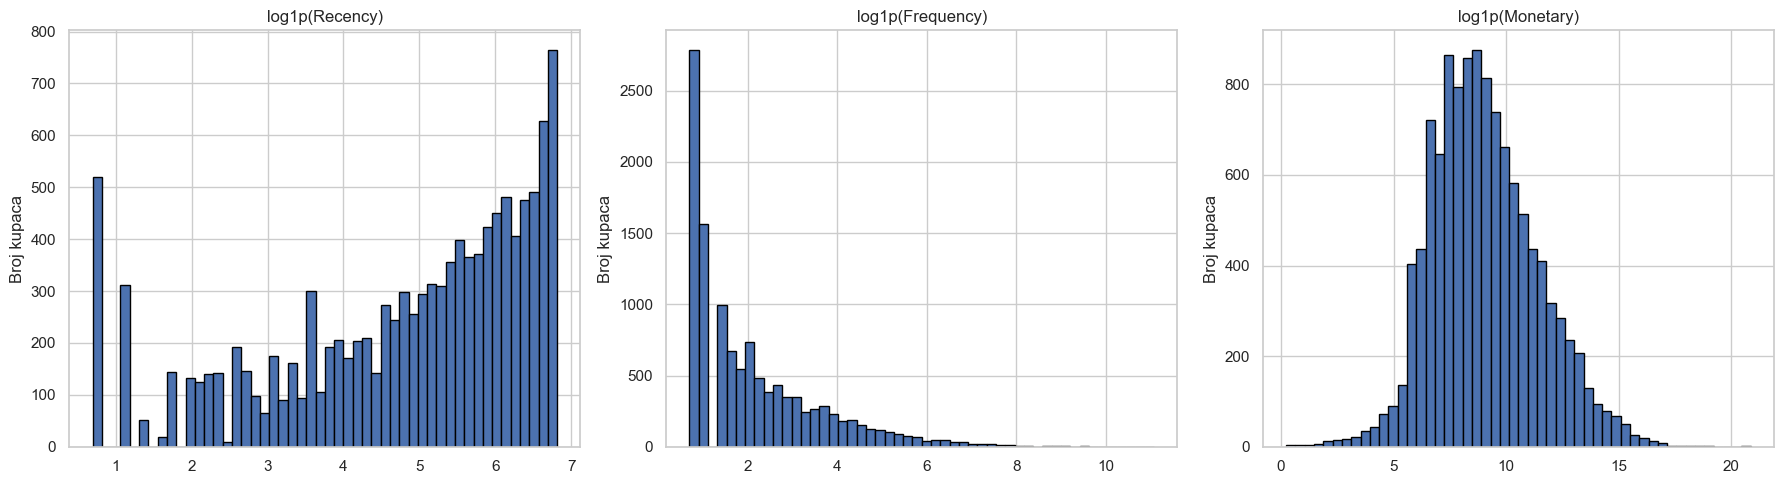

       Recency  Frequency      Monetary
count 11753.00   11753.00      11753.00
mean    282.71      68.91     335076.55
std     275.69     824.55   11097154.96
min       1.00       1.00          0.26
25%      37.00       2.00       1598.08
50%     191.00       4.00       6726.50
75%     475.00      17.00      36899.13
max     912.00   65043.00 1153153861.28


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    np.log1p(rfm[col]).hist(bins=50, ax=ax, edgecolor='black')
    ax.set_title(f'log1p({col})')
    ax.set_ylabel('Broj kupaca')
plt.tight_layout()
plt.show()

# Osnovne statistike
print(rfm[['Recency', 'Frequency', 'Monetary']].describe())

In [4]:
# Top 10 kupaca po svakoj dimenziji
print("=== Top 10 Frequency ===")
print(rfm.nlargest(10, 'Frequency')[['CustomerID', 'Recency', 'Frequency', 'Monetary']])

print("\n=== Top 10 Monetary ===")
print(rfm.nlargest(10, 'Monetary')[['CustomerID', 'Recency', 'Frequency', 'Monetary']])

print("\n=== Osnovne statistike ===")
print(rfm[['Recency', 'Frequency', 'Monetary']].describe(percentiles=[.25, .5, .75, .9, .95, .99]))

=== Top 10 Frequency ===
       CustomerID  Recency  Frequency     Monetary
1722        18161        1      65043  13021963.99
6723       224597        1      40352 175400049.15
1723        18163        1      17723   2307673.56
1945        19118        1      15093  20616481.12
2251        21141        1      14995  22294089.86
1739        18210        1      13278  13320617.73
1718        18145        1      10935   1415262.41
299          2042        1       9547   3693052.22
2137        20624        1       8307   4350581.02
11726      294128        1       8292  12482653.19

=== Top 10 Monetary ===
      CustomerID  Recency  Frequency      Monetary
6678      224302        1       1287 1153153861.28
2401       22412        1        166  201421183.33
6723      224597        1      40352  175400049.15
5878      217135        5         88  140185569.81
2422       22893        1         26   94975212.48
2260       21154        2        802   55794078.16
2261       21155      479       

In [5]:
# Recency: niži = bolji → invertirana skala (5 = najnoviji)
rfm['R_score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1])
# Frequency i Monetary: viši = bolji
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])
rfm['M_score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5])

rfm['RFM_score'] = rfm['R_score'].astype(int) + rfm['F_score'].astype(int) + rfm['M_score'].astype(int)

print(rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_score', 'F_score', 'M_score', 'RFM_score']].head(10))

   CustomerID  Recency  Frequency  Monetary R_score F_score M_score  RFM_score
0          13      582          1   2320.00       1       1       2          4
1          16      392          1   4165.00       2       1       3          6
2          22       30          9  11025.00       4       4       3         11
3          26      700          8   7475.95       1       4       3          8
4          35      707         26  36471.94       1       5       4         10
5          37      282          4   5850.00       3       3       3          9
6          40        7        150 171206.44       5       5       5         15
7          49      321          6   8987.50       2       3       3          8
8          59       85         14  22880.00       4       4       4         12
9          69      534          7   9247.50       2       3       3          8


In [6]:
# Concatenated segment string
rfm['RFM_segment'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)

# Humane labele bazirane na R i F scoreovima (standard mapping)
seg_map = {
    r'5[4-5]': 'Champions',
    r'[3-4][4-5]': 'Loyal Customers',
    r'[4-5][2-3]': 'Potential Loyalists',
    r'51': 'New Customers',
    r'41': 'Promising',
    r'3[1-2]' : 'About To Sleep',
    r'33': 'Need Attention',
    r'[1-2][3-4]': 'At Risk',
    r'[1-2][1-2]': 'Hibernating',
    r'[1-2]5': 'Cant Lose Them',
}

def assign_segment(row):
    rf = str(row['R_score']) + str(row['F_score'])
    for pattern, label in seg_map.items():
        import re
        if re.match(pattern, rf):
            return label
    return 'Other'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)
print(rfm['Segment'].value_counts())

Segment
Hibernating            3113
Loyal Customers        2155
Champions              1931
At Risk                1446
Potential Loyalists    1245
About To Sleep          827
Need Attention          678
Promising               171
Cant Lose Them          135
New Customers            52
Name: count, dtype: int64


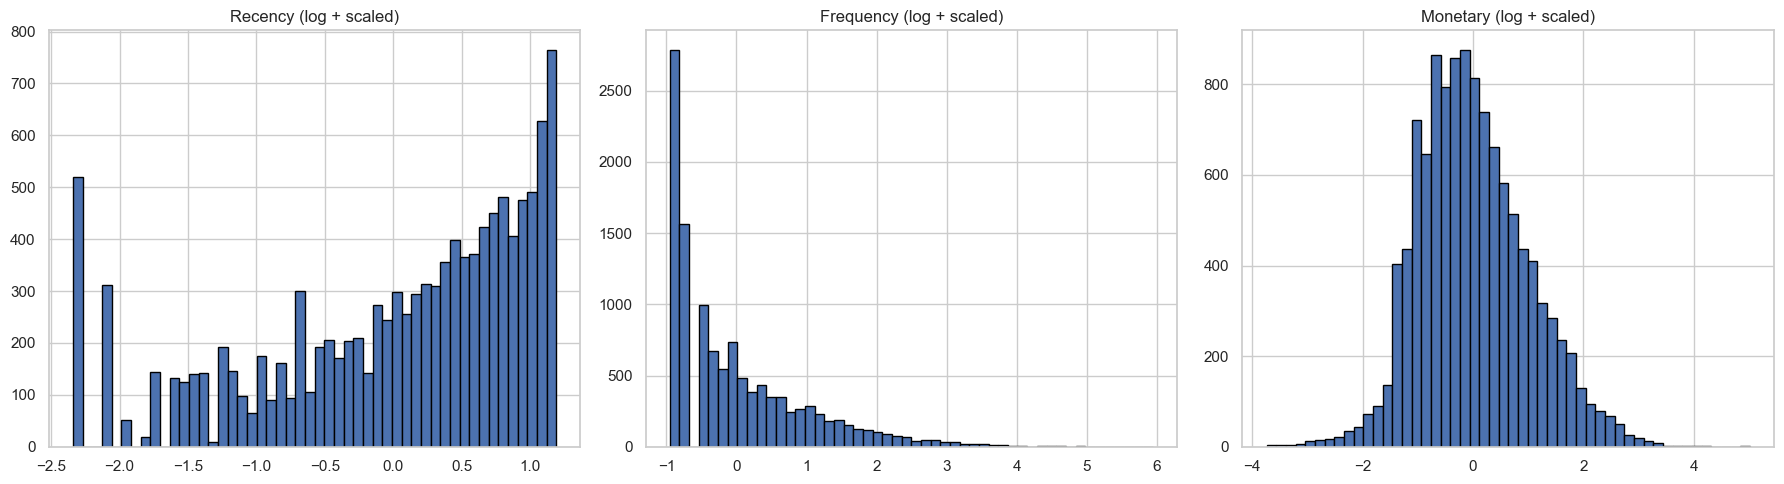

In [7]:
# Log1p da izbjegnemo log(0)
rfm_log = rfm[['Recency', 'Frequency', 'Monetary']].copy()
rfm_log['Monetary'] = np.log1p(rfm_log['Monetary'])
rfm_log['Frequency'] = np.log1p(rfm_log['Frequency'])
rfm_log['Recency'] = np.log1p(rfm_log['Recency'])

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])

# Provjera distribucija nakon transformacije
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, rfm_scaled.columns):
    rfm_scaled[col].hist(bins=50, ax=ax, edgecolor='black')
    ax.set_title(f'{col} (log + scaled)')
plt.tight_layout()
plt.show()

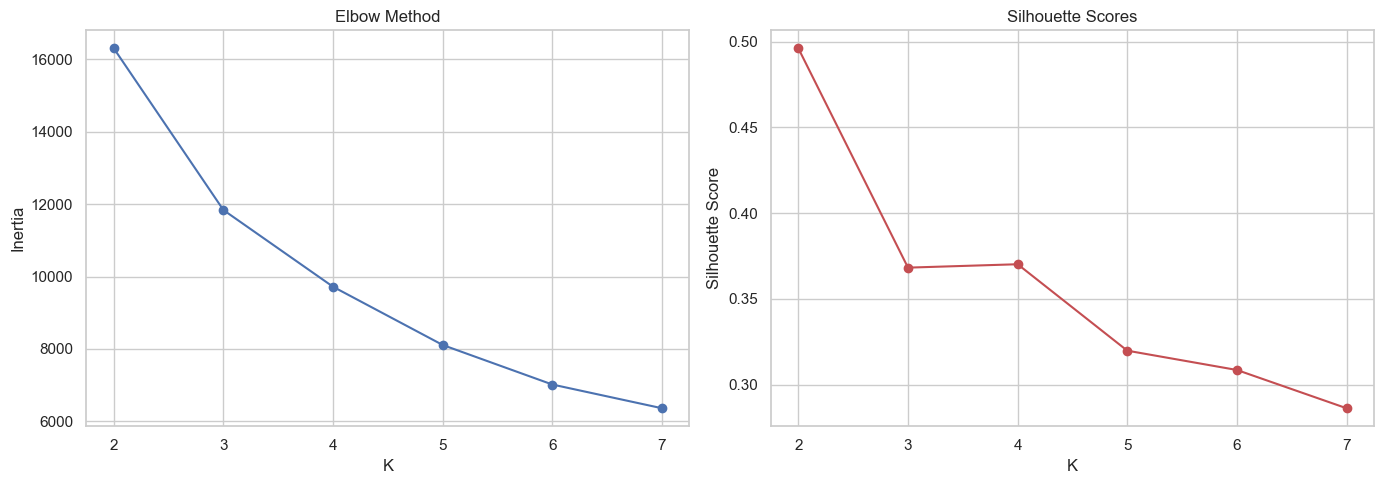

K=2: silhouette=0.4960
K=3: silhouette=0.3682
K=4: silhouette=0.3702
K=5: silhouette=0.3198
K=6: silhouette=0.3086
K=7: silhouette=0.2863


In [8]:
inertia = []
sil_scores = []
K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(rfm_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(K_range, inertia, 'bo-')
ax1.set_xlabel('K')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method')

ax2.plot(K_range, sil_scores, 'ro-')
ax2.set_xlabel('K')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Scores')

plt.tight_layout()
plt.show()

for k, s in zip(K_range, sil_scores):
    print(f'K={k}: silhouette={s:.4f}')

# cini se da bi K=4 bio nekako najoptimalniji

In [9]:
for k in [3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    rfm[f'K{k}'] = km.fit_predict(rfm_scaled)
    print(f'\n=== K={k} ===')
    print(rfm.groupby(f'K{k}')[['Recency', 'Frequency', 'Monetary']].mean().round(1))
    print(f'Veličine: {rfm[f"K{k}"].value_counts().sort_index().to_dict()}')


=== K=3 ===
    Recency  Frequency   Monetary
K3                               
0     21.50     384.50 1904671.80
1    155.10      13.90   61535.30
2    466.50       2.20    3148.00
Veličine: {0: 1923, 1: 4188, 2: 5642}

=== K=4 ===
    Recency  Frequency   Monetary
K4                               
0     30.80      10.00   14119.70
1     17.90     413.10 2023461.60
2    476.40       2.10    2692.60
3    253.60      16.70  109237.20
Veličine: {0: 1865, 1: 1773, 2: 5277, 3: 2838}


In [10]:
OPTIMAL_K = 4

km_final = KMeans(n_clusters=OPTIMAL_K, n_init=10, random_state=42)
rfm['Cluster'] = km_final.fit_predict(rfm_scaled)

# Profiliranje klastera
cluster_profile = rfm.groupby('Cluster').agg(
    Recency_mean=('Recency', 'mean'),
    Frequency_mean=('Frequency', 'mean'),
    Monetary_mean=('Monetary', 'mean'),
    Monetary_median=('Monetary', 'median'),
    Count=('CustomerID', 'count')
).round(1)

print(cluster_profile)

         Recency_mean  Frequency_mean  Monetary_mean  Monetary_median  Count
Cluster                                                                     
0               30.80           10.00       14119.70          6959.00   1865
1               17.90          413.10     2023461.60        229461.30   1773
2              476.40            2.10        2692.60          1548.40   5277
3              253.60           16.70      109237.20         28379.50   2838


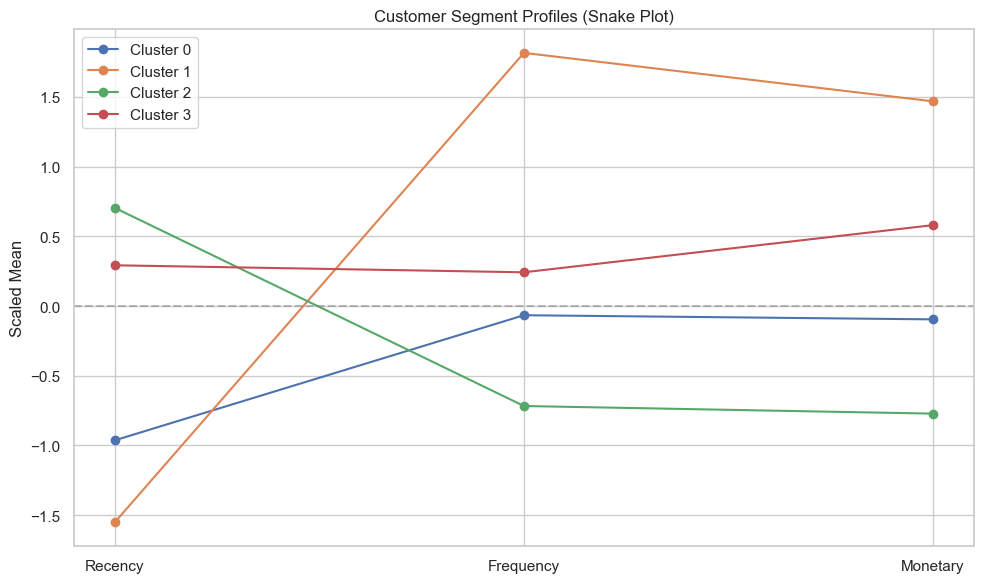

In [11]:
rfm_scaled['Cluster'] = rfm['Cluster'].values
cluster_means = rfm_scaled.groupby('Cluster').mean()

fig, ax = plt.subplots(figsize=(10, 6))
for cluster in cluster_means.index:
    ax.plot(['Recency', 'Frequency', 'Monetary'],
            cluster_means.loc[cluster],
            marker='o', label=f'Cluster {cluster}')
ax.set_ylabel('Scaled Mean')
ax.set_title('Customer Segment Profiles (Snake Plot)')
ax.legend()
ax.axhline(0, color='grey', ls='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [12]:
%matplotlib inline

In [13]:
import plotly.express as px

fig = px.scatter_3d(
    rfm,
    x=rfm_scaled['Recency'],
    y=rfm_scaled['Frequency'],
    z=rfm_scaled['Monetary'],
    color=rfm['Cluster'].astype(str),
    opacity=0.4,
    title='K-Means Clusters (3D)',
    labels={'x': 'Recency', 'y': 'Frequency', 'z': 'Monetary', 'color': 'Cluster'}
)
fig.write_html('../visualization/clusters_3d.html')
print('Otvori clusters_3d.html u browseru!')

Otvori clusters_3d.html u browseru!


In [14]:
cluster_names = {
    0: 'Hibernating',      
    1: 'Whales / Champions',
    2: 'Mid-Tier At Risk',
    3: 'Active Small Buyers'
}
rfm['Cluster_name'] = rfm['Cluster'].map(cluster_names)
print(rfm['Cluster_name'].value_counts())

Cluster_name
Mid-Tier At Risk       5277
Active Small Buyers    2838
Hibernating            1865
Whales / Champions     1773
Name: count, dtype: int64


In [15]:
rfm.to_csv('../data/processed/rfm_segments.csv', index=False)
print(f'Spremljeno! Shape: {rfm.shape}')
print(rfm.columns.tolist())

Spremljeno! Shape: (11753, 14)
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_score', 'F_score', 'M_score', 'RFM_score', 'RFM_segment', 'Segment', 'K3', 'K4', 'Cluster', 'Cluster_name']
